# Beyond Binary Search: 8 Variants, When They Win, and Proof

Standard binary search is $O(\log N)$ and *optimal in the comparison model when you know nothing about your data*. Every variant below wins by **exploiting something extra**: query skew, data distribution, unknown size, memory hierarchy, or hardware behaviour.

| # | Technique | What it exploits | Honest headline |
|---|-----------|------------------|-----------------|
| 1 | Boundary-aware (check `low`/`high` each step) | Queries hitting the edges / out-of-range misses | Great for edges, **worse** for typical queries |
| 2 | Deferred-equality (single-comparison loop) | Cost per iteration | ~2x fewer comparisons in the true worst case |
| 3 | Interpolation search | Uniformly distributed keys | $O(\log\log N)$ avg, $O(N)$ worst |
| 4 | Interpolation + binary hybrid | Uniform data **and** a safety net | Fixes interpolation's worst case |
| 5 | Exponential / galloping | Target near the front, or unknown size | $O(\log i)$ instead of $O(\log N)$ |
| 6 | Learned-index search | Any *learnable* distribution (even skewed) | ~3x fewer reads of the big array |
| 7 | Eytzinger layout (+ branchless) | CPU cache & prefetching | 2-5x faster wall-clock in C |
| 8 | Meta / bitwise search | Predictable, division-free loop | Fixed step count, branch-friendly |

**How we measure.** Wall-clock time in Python is noisy and hides hardware effects, so every scenario reports:

* **Comparisons** (key vs. element) - the algorithmic cost, deterministic and fair
* **Time per query** (microseconds) - what you would actually feel in Python
* **Extra space** - measured with `tracemalloc` where it matters

Scenario 7 also runs a real **C benchmark**, because cache effects are impossible to show in pure Python.

In [3]:
import time, math, bisect, random, tracemalloc, subprocess, os, shutil
import numpy as np
import pandas as pd

random.seed(42); np.random.seed(42)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

RESULTS = []   # every scenario appends here; the final cell summarises them


def run(fn, arr, targets, **kw):
    # Run fn over all targets. Returns (avg comparisons, avg microseconds per query)
    total_cmp = 0
    t0 = time.perf_counter()
    for t in targets:
        _, c = fn(arr, t, **kw)
        total_cmp += c
    dt = time.perf_counter() - t0
    return total_cmp / len(targets), dt / len(targets) * 1e6


def verify(fn, arr, targets, **kw):
    # Every variant must agree with bisect (arrays here have unique keys).
    for t in targets:
        i = bisect.bisect_left(arr, t)
        expected = i if i < len(arr) and arr[i] == t else -1
        got, _ = fn(arr, t, **kw)
        assert got == expected, f"{fn.__name__} wrong for {t}: got {got}, expected {expected}"


def peak_bytes(fn, *args):
    tracemalloc.start()
    fn(*args)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    return peak


def record(scenario, workload, base_c, tech_c, base_us, tech_us):
    RESULTS.append(dict(scenario=scenario, workload=workload,
                        normal_cmp=base_c, tech_cmp=tech_c,
                        cmp_speedup=base_c / tech_c,
                        normal_us=base_us, tech_us=tech_us,
                        time_speedup=base_us / tech_us))


def show(rows, cols):
    print(pd.DataFrame(rows, columns=cols).to_string(index=False))


# ---------- Friendly output helpers (used by every scenario) ----------
def _num(v):
    return f"{v:,.0f}" if v >= 1000 else f"{v:,.1f}"


def _times(r):
    return f"{r:,.0f}x" if r >= 100 else f"{r:.1f}x"


def compare(situation, entries, unit="comparisons", normal_first=True):
    # Print one situation as a mini bar-chart. entries = [(name, cost, extra_text), ...]; the FIRST entry is "normal" binary search.
    costs = [e[1] for e in entries]
    hi, lo = max(costs), max(min(costs), 1e-9)
    use_log = hi / lo > 50
    print(f"\n▶ SITUATION: {situation}")
    for name, cost, extra in entries:
        if use_log:
            frac = (math.log10(max(cost, lo)) - math.log10(lo) + 0.2) / (math.log10(hi) - math.log10(lo) + 0.2)
        else:
            frac = cost / hi
        bar = "█" * max(1, round(frac * 28))
        print(f"    {name:<30} {bar:<29} {_num(cost):>9} {unit}   {extra}")
    if use_log:
        print("    (bars are drawn on a log scale because the numbers differ hugely)")
    base = entries[0][1]
    for name, cost, _ in entries[1:]:
        r = base / cost
        if r >= 1.2:   verdict = f"{_times(r)} LESS work than normal search   [WIN]"
        elif r <= 0.8: verdict = f"{_times(1 / r)} MORE work than normal search   [LOSS - normal is better here]"
        else:          verdict = "about the same as normal search   [NEUTRAL]"
        print(f"    => {name}: {verdict}")

## How to read the results in this notebook (30-second guide)

Each test prints a small block like this:

```
▶ SITUATION: Random searches inside the list            <- what we are testing
    Normal binary search   ███████████████████████████   36.8 comparisons   5.0 microseconds per search
    New technique          ███████████████               21.0 comparisons   4.2 microseconds per search
    => New technique: 1.8x LESS work than normal search   [WIN]
```

| Word | Meaning |
|---|---|
| **Comparison** | One "is this element equal to / smaller than my target?" check. This is the honest measure of how much *thinking* the algorithm does. **Fewer is better.** |
| **Microsecond (us)** | One millionth of a second - how long one search took in Python. Fewer is better, but it is noisy (your computer, other programs...). |
| **Nanosecond (ns)** | One billionth of a second - used for the C benchmark where searches are much faster. |
| **Bar (█)** | Longer bar = more work = **worse**. Compare bars to compare techniques. |
| **[WIN] / [NEUTRAL] / [LOSS]** | Compared with normal binary search *on that situation*: at least 1.2x less work = WIN, within about 20% = NEUTRAL, more work = LOSS. |

Two things to remember: a technique that **wins in one situation often loses in another** (that is the whole point of this notebook), and **"normal binary search"** always means the textbook version defined in the next cell.

## 0. Baseline: Standard Binary Search

**How it works.** Keep a window `[low, high]`. Look at the middle element, discard the half that cannot contain the target, repeat.

**Cost model.** Each iteration does up to **2 comparisons** (`==` then `<`) and halves the window, so the worst case is about $2\log_2 N$ comparisons.

* Time: $O(\log N)$ - Space: $O(1)$

Everything below is measured against this function.

In [4]:
def binary_search(arr, target):
    lo, hi = 0, len(arr) - 1
    c = 0
    while lo <= hi:
        mid = (lo + hi) // 2
        c += 1
        if arr[mid] == target:
            return mid, c
        c += 1
        if arr[mid] < target:
            lo = mid + 1
        else:
            hi = mid - 1
    return -1, c


arr = list(range(0, 2_000_000, 2))          # 1M sorted even numbers (odd numbers are guaranteed misses)
verify(binary_search, arr, random.sample(arr, 200) + [1, 3, -5, 10**9])
print(f"Our test list has {len(arr):,} sorted numbers.")
print(f"Halving a list of that size takes about log2({len(arr):,}) = {math.log2(len(arr)):.0f} steps, and each step does up to 2 comparisons.")
print(f"Extra memory used by one search: about {peak_bytes(binary_search, arr, arr[500_000])} bytes (a few variables) -> constant space, O(1)")

Our test list has 1,000,000 sorted numbers.
Halving a list of that size takes about log2(1,000,000) = 20 steps, and each step does up to 2 comparisons.
Extra memory used by one search: about 140 bytes (a few variables) -> constant space, O(1)


## 1. Boundary-Aware Binary Search (the one you read about)

**Idea.** In every iteration, also look at `arr[low]` and `arr[high]` next to `arr[mid]`.

* If the target equals either edge, return immediately.
* If `target < arr[low]` or `target > arr[high]`, the target cannot exist, so return `-1` immediately.

**How it differs.** Standard binary search never notices that the target is *at* or *outside* the current window's edges; it just keeps halving. This variant notices instantly.

**Where it wins (real scenarios)**
* **Time-series / log stores:** "give me the latest record" (`arr[-1]`) is the most common query.
* **Negative lookups:** dedup checks, Bloom-filter fallbacks, or ID validation where most keys are out of range. Standard search burns ~20 steps to say "not here"; this says it in 1.

**The honest catch.** It does **not** improve the worst case for keys that fall *inside* the range. It makes each iteration 3x heavier (3 element reads, up to 6 comparisons instead of 2), so for ordinary random hits it is **slower**. Use it only when the workload is skewed toward the edges.

* Time: best $O(1)$, worst $O(\log N)$ - Space: $O(1)$

In [5]:
def boundary_aware_search(arr, target):
    lo, hi = 0, len(arr) - 1
    c = 0
    while lo <= hi:
        c += 2                                   # range guard: two comparisons
        if target < arr[lo] or target > arr[hi]:
            return -1, c                         # provably absent
        c += 2                                   # edge hits
        if arr[lo] == target: return lo, c
        if arr[hi] == target: return hi, c
        mid = (lo + hi) // 2
        c += 1
        if arr[mid] == target: return mid, c
        c += 1
        if arr[mid] < target: lo = mid + 1
        else:                 hi = mid - 1
    return -1, c


verify(boundary_aware_search, arr, random.sample(arr, 200) + [1, 3, -5, 10**9, arr[0], arr[-1]])

workloads = {
    "Edge hits (first/last element)":   [arr[0], arr[-1]] * 500,
    "Out-of-range misses":              [-7, 10**9] * 500,
    "Random hits inside the range":     random.sample(arr, 1000),
}
print(f"Searching a sorted list of {len(arr):,} numbers. Lower bar = less work = better.")
for name, tg in workloads.items():
    bc, bu = run(binary_search, arr, tg)
    tc, tu = run(boundary_aware_search, arr, tg)
    record("1 Boundary-aware", name, bc, tc, bu, tu)
    compare(name, [("Normal binary search", bc, f"{bu:.2f} microseconds per search"),
                   ("Boundary-aware search", tc, f"{tu:.2f} microseconds per search")])

Searching a sorted list of 1,000,000 numbers. Lower bar = less work = better.

▶ SITUATION: Edge hits (first/last element)
    Normal binary search           ████████████████████████████       38.0 comparisons   4.94 microseconds per search
    Boundary-aware search          ███                                 4.0 comparisons   0.63 microseconds per search
    => Boundary-aware search: 9.5x LESS work than normal search   [WIN]

▶ SITUATION: Out-of-range misses
    Normal binary search           ████████████████████████████       39.0 comparisons   3.10 microseconds per search
    Boundary-aware search          █                                   2.0 comparisons   0.28 microseconds per search
    => Boundary-aware search: 19.5x LESS work than normal search   [WIN]

▶ SITUATION: Random hits inside the range
    Normal binary search           ██████████                         36.7 comparisons   5.79 microseconds per search
    Boundary-aware search          ████████████████████████████  

**Reading the result.** Edge hits and out-of-range misses collapse to a *constant* number of comparisons (the speedup is the whole ~$\log N$ factor). But on random hits inside the range the speedup drops **below 1x**: you pay for three probes per step and almost never cash the edge check in. This is exactly why it is "worth knowing" but not a default.

**Rule of thumb:** measure your query distribution first. If more than roughly 5-10% of queries land on the edges or outside the range, it pays off.

## 2. Deferred-Equality Binary Search (single comparison per iteration)

If your goal is to **tackle the worst case**, this is the classic that actually does it (Bentley, *Programming Pearls*; it is how C++ `lower_bound` works).

**Idea.** Standard search asks two questions per step (`==`? then `<`?). Ask only **one**: "is `arr[mid] < target`?" Keep the invariant *answer is in `[lo, hi)`*, never exit early, and test equality **once at the end**.

**How it differs.**

| | Standard | Deferred-equality |
|---|---|---|
| Comparisons per step | up to 2 | exactly 1 |
| Early exit on hit | yes (saves ~1 step on average) | no |
| Total comparisons (worst) | $\approx 2\log_2 N$ | $\log_2 N + 1$ |
| Loop branches | 2 unpredictable | 1 unpredictable |

Where it wins: every **miss** (absent key) and every worst-case hit, and anywhere comparisons are expensive (strings, tuples, custom `__lt__`, database keys).

* Time: $O(\log N)$ with ~half the constant - Space: $O(1)$

In [7]:
def deferred_equality_search(arr, target):
    lo, hi = 0, len(arr)                 # search in [lo, hi)
    c = 0
    while lo < hi:
        mid = (lo + hi) // 2
        c += 1
        if arr[mid] < target: lo = mid + 1
        else:                 hi = mid
    c += 1                               # one equality check at the very end
    if lo < len(arr) and arr[lo] == target:
        return lo, c
    return -1, c


verify(deferred_equality_search, arr, random.sample(arr, 200) + [1, 3, -5, 10**9, arr[0], arr[-1]])

present = random.sample(arr, 2000)
absent  = [x + 1 for x in random.sample(arr[:-1], 2000)]      # odd numbers inside the range = guaranteed misses
print(f"Searching a sorted list of {len(arr):,} numbers.")
for name, tg in {"Numbers that ARE in the list": present, "Numbers that are NOT in the list (the worst case)": absent}.items():
    bc, bu = run(binary_search, arr, tg)
    tc, tu = run(deferred_equality_search, arr, tg)
    record("2 Deferred-equality", name, bc, tc, bu, tu)
    compare(name, [("Normal binary search", bc, f"{bu:.2f} microseconds per search"),
                   ("Deferred-equality search", tc, f"{tu:.2f} microseconds per search")])
print(f"\nWhy: normal search asks 2 questions per step (about 2 x {math.log2(len(arr)):.0f} = {2*math.log2(len(arr)):.0f} comparisons); deferred-equality asks 1 per step (about {math.log2(len(arr))+1:.0f}).")

Searching a sorted list of 1,000,000 numbers.

▶ SITUATION: Numbers that ARE in the list
    Normal binary search           ████████████████████████████       37.0 comparisons   5.46 microseconds per search
    Deferred-equality search       ████████████████                   21.0 comparisons   5.15 microseconds per search
    => Deferred-equality search: 1.8x LESS work than normal search   [WIN]

▶ SITUATION: Numbers that are NOT in the list (the worst case)
    Normal binary search           ████████████████████████████       39.9 comparisons   4.75 microseconds per search
    Deferred-equality search       ███████████████                    21.0 comparisons   3.59 microseconds per search
    => Deferred-equality search: 1.9x LESS work than normal search   [WIN]

Why: normal search asks 2 questions per step (about 2 x 20 = 40 comparisons); deferred-equality asks 1 per step (about 21).


**Reading the result.** On misses (the true worst case) comparisons drop by almost exactly **2x**, matching the theory. On hits the gain is smaller because standard search sometimes exits a step early. Note that in *Python wall-clock* the gain is small: list indexing and interpreter overhead dominate, so trust the comparison column for the algorithmic claim (it matters most when comparisons are expensive: strings, tuples, custom keys). This variant also sets up everything that follows: the branchless and Eytzinger versions in Scenarios 7 and 8 are built on the same "one comparison per step" loop.

## 3. Interpolation Search (the "dictionary" method)

**Idea.** Standard search always jumps to the *middle*. But if you look up "Zebra" in a dictionary you open near the *end*. Interpolation search uses the values at the edges to **estimate** the position:

$$pos = low + \frac{target - arr[low]}{arr[high] - arr[low]} \times (high - low)$$

**How it differs.** Standard halves the *index range* no matter what. Interpolation shrinks the range based on *where the value should be*, so on evenly spread keys it lands almost exactly on the target.

**Where it wins:** auto-increment primary keys, sequence numbers, evenly sampled timestamps, sensor readings on a fixed clock.

**Where it loses:** skewed data (exponential growth, clustered IDs, log-normal latencies). The guess is consistently wrong and it degrades toward a linear scan.

* Time: average $O(\log\log N)$, worst $O(N)$ - Space: $O(1)$
* For 1 billion uniform keys: ~5 probes vs ~30 for binary search.

In [8]:
def interpolation_search(arr, target):
    lo, hi = 0, len(arr) - 1
    c = 0
    while lo <= hi:
        c += 2
        if not (arr[lo] <= target <= arr[hi]):
            return -1, c
        if arr[hi] == arr[lo]:
            pos = lo
        else:
            pos = lo + int((hi - lo) * (target - arr[lo]) / (arr[hi] - arr[lo]))
        c += 1
        if arr[pos] == target:
            return pos, c
        c += 1
        if arr[pos] < target: lo = pos + 1
        else:                 hi = pos - 1
    return -1, c


# --- Dataset A: uniform (sequential IDs with small jitter) --------------------------------------
N = 2_000_000
uniform = sorted(set(np.cumsum(np.random.randint(1, 6, size=N)).tolist()))
# --- Dataset B: heavily skewed (exponential growth) -----------------------------------------------
M = 200_000
skewed = [1.0001 ** i for i in range(M)]

tg_u = random.sample(uniform, 1000)
tg_s = random.sample(skewed[:M // 3], 150)          # targets in the dense low region

verify(interpolation_search, uniform, tg_u[:100]); verify(interpolation_search, skewed, tg_s[:30])

for label, data, tg in [(f"EVENLY spread data ({len(uniform):,} sequential IDs)", uniform, tg_u),
                        (f"HEAVILY SKEWED data ({len(skewed):,} numbers growing exponentially)", skewed, tg_s)]:
    bc, bu = run(binary_search, data, tg)
    tc, tu = run(interpolation_search, data, tg)
    record("3 Interpolation", label, bc, tc, bu, tu)
    compare(label, [("Normal binary search", bc, f"{bu:.2f} microseconds per search"),
                    ("Interpolation search", tc, f"{tu:,.2f} microseconds per search")])


▶ SITUATION: EVENLY spread data (2,000,000 sequential IDs)
    Normal binary search           ████████████████████████████       38.6 comparisons   4.73 microseconds per search
    Interpolation search           ██████████                         13.3 comparisons   1.90 microseconds per search
    => Interpolation search: 2.9x LESS work than normal search   [WIN]

▶ SITUATION: HEAVILY SKEWED data (200,000 numbers growing exponentially)
    Normal binary search           █                                  32.5 comparisons   3.23 microseconds per search
    Interpolation search           ████████████████████████████    140,585 comparisons   14,032.49 microseconds per search
    (bars are drawn on a log scale because the numbers differ hugely)
    => Interpolation search: 4,327x MORE work than normal search   [LOSS - normal is better here]


It is doing 4 distinct mathematical steps:

The Value Span: (arr[hi] - arr[lo])

What is the difference between the smallest and largest numbers in our current window?

The Target Distance: (target - arr[lo])

How far is our target number from the smallest number?

The Ratio (Percentage): Target Distance / Value Span

Where does our target fall as a percentage? (e.g., If the range is 0 to 100, and the target is 80, the ratio is 0.80 or 80%).

The Index Jump: lo + (Ratio * (hi - lo))

Multiply that percentage by the number of indices available, and jump exactly to that index.

**Reading the result.**

* **Uniform data:** interpolation needs only a handful of comparisons versus ~40 for binary search. That is the $\log\log N$ effect in action.
* **Skewed data:** the speedup flips to **far below 1x**. Interpolation needs on the order of **100,000+ comparisons** (thousands of times worse) where binary search always needs ~35. That unbounded worst case is why raw interpolation search is dangerous in production, and it leads directly to the next technique.

## 4. Interpolation-Binary Hybrid (the safe version)

**Idea.** Keep interpolation's speed on friendly data, but **guarantee** binary search's worst case. Alternate the two guesses:

* odd steps: interpolation guess
* even steps: plain midpoint

**Why it works.** Every second step is a true midpoint, so the window at least halves every 2 steps. The worst case is therefore bounded by $2\log_2 N$ iterations no matter how nasty the data is. When the data *is* uniform, the interpolation steps still land near the target, so you keep most of the speedup.

This is the practical answer to "how do I fix the worst case": pay at most 2x in the bad case, win big in the good case.

* Time: average $O(\log\log N)$ on uniform data, worst $O(\log N)$ - Space: $O(1)$

In [1]:
def hybrid_interpolation_search(arr, target):
    lo, hi = 0, len(arr) - 1
    c = 0
    use_interp = True
    while lo <= hi:
        c += 2
        if not (arr[lo] <= target <= arr[hi]):
            return -1, c
        if use_interp and arr[hi] != arr[lo]:
            pos = lo + int((hi - lo) * (target - arr[lo]) / (arr[hi] - arr[lo]))
        else:
            pos = (lo + hi) // 2                 # guaranteed halving step
        use_interp = not use_interp
        c += 1
        if arr[pos] == target: return pos, c
        c += 1
        if arr[pos] < target: lo = pos + 1
        else:                 hi = pos - 1
    return -1, c


verify(hybrid_interpolation_search, uniform, tg_u[:100]); verify(hybrid_interpolation_search, skewed, tg_s[:50])

for label, data, tg in [(f"EVENLY spread data ({len(uniform):,} sequential IDs)", uniform, tg_u),
                        (f"HEAVILY SKEWED data ({len(skewed):,} numbers growing exponentially)", skewed, tg_s)]:
    bc, bu = run(binary_search, data, tg)
    ic, iu = run(interpolation_search, data, tg)
    hc, hu = run(hybrid_interpolation_search, data, tg)
    record("4 Interp+binary hybrid", label, bc, hc, bu, hu)
    compare(label, [("Normal binary search", bc, f"{bu:.2f} microseconds per search"),
                    ("Raw interpolation (Scenario 3)", ic, f"{iu:,.2f} microseconds per search"),
                    ("Hybrid (interp + binary)", hc, f"{hu:.2f} microseconds per search")])
ceiling = 8 * math.log2(len(skewed))
print(f"\nThe safety guarantee: no matter how skewed the data is, the hybrid can never need more than about {ceiling:.0f} comparisons per search")
print("(2 x log2(N) steps, each step at most 4 comparisons). Raw interpolation has NO such limit - it needed more than 100,000 above.")

NameError: name 'verify' is not defined

1. How it Escapes the $O(N)$ Crawl (Dataset B: Skewed)In the previous scenario with skewed data, raw interpolation guessed index 0, then index 1, then index 2, crawling forward one step at a time for 140,000 iterations.
Here is what the Hybrid does differently on that exact same skewed dataset:
Turn 1 (Interpolation): It calculates the ratio, gets fooled by the massive skew, and guesses pos = 0.
 It checks index 0, misses, and updates lo = 1. 
 The search space only shrank by 1 item.

Turn 2 (Forced Binary): Because use_interp is now False, it ignores the math formula entirely and does pos = (lo + hi) // 2.
 If the remaining array has 199,999 items, it forcefully jumps to index 100,000. The search space is instantly chopped in half.
  
Turn 3 (Interpolation): It tries the math formula again on the new boundaries. It might guess poorly again and only shrink the array by 1 item.
  
  Turn 4 (Forced Binary): It forcefully chops the remaining 100,000 items down to 50,000.The Guarantee: Even if the interpolation guesses are completely useless every time, the array is guaranteed to be cut in half at least every 2 iterations.
  
   This caps the worst-case time complexity at $O(2 \log_2 N)$.As your benchmark showed, it brought the comparisons on skewed data crashing down from 142,604 back down to 62.7.

**Reading the result.** On skewed data raw interpolation explodes, while the hybrid stays within a small constant multiple of binary search (its guaranteed bound). On uniform data the hybrid keeps most of the interpolation win. The cost of the safety net is visible but bounded: on skewed data the hybrid is ~2x slower than plain binary search (that is the price of insurance), yet thousands of times better than raw interpolation. Compare this with Scenario 1: boundary checks do not protect you from the bad case, this does.

## 5. Exponential (Galloping) Search

**Idea.** Do not start with the whole array. Probe indices $1, 2, 4, 8, 16, \dots$ until you overshoot the target, then binary search only inside that last window $[2^{k-1}, 2^k]$.

**How it differs.** Cost depends on **where the target is** ($i$), not on how big the array is ($N$): $O(\log i)$ instead of $O(\log N)$.

**Where it wins**
* **Unbounded / streaming data** where `len()` is unknown (paginated APIs, append-only logs, infinite generators). Standard binary search cannot even start without an upper bound.
* **Skewed toward the front:** "most recent first" storage, hot keys near index 0.
* **Merging sorted runs:** Python's Timsort uses galloping mode when one run keeps winning.

**The catch.** If the target is at the far end you pay about 2x binary search.

* Time: $O(\log i)$ - Space: $O(1)$

In [10]:
def exponential_search(arr, target):
    n = len(arr)
    c = 1
    if n == 0: return -1, 0
    if arr[0] == target: return 0, c
    bound = 1
    while bound < n:                       # gallop: 1, 2, 4, 8, ...
        c += 1
        if arr[bound] > target: break
        bound *= 2
    lo, hi = bound // 2, min(bound, n - 1) # binary search only inside the last window
    while lo <= hi:
        mid = (lo + hi) // 2
        c += 1
        if arr[mid] == target: return mid, c
        c += 1
        if arr[mid] < target: lo = mid + 1
        else:                 hi = mid - 1
    return -1, c


big = list(range(10_000_000))
verify(exponential_search, big, [0, 1, 2, 15, 999, 5_000_000, 9_999_999, -1, 10**9])

# Sweep the target position i: cost of galloping tracks log(i), standard is flat at ~log(N)
positions = [1, 10, 100, 1_000, 10_000, 100_000, 1_000_000, 9_999_999]
print(f"Searching a sorted list of {len(big):,} numbers. We move the target further and further from the front:")
for p in positions:
    tg = [big[p]] * 200
    bc, bu = run(binary_search, big, tg)
    ec, eu = run(exponential_search, big, tg)
    if p in (10, 1_000):
        record("5 Exponential/galloping", f"Target at index {p:,} of 10M", bc, ec, bu, eu)
    where = "the very front" if p == 1 else ("the very END of the list" if p == len(big) - 1 else f"position {p:,} from the front")
    compare(f"target is at {where}", [("Normal binary search", bc, f"{bu:.2f} microseconds per search"),
                                     ("Exponential (galloping) search", ec, f"{eu:.2f} microseconds per search")])

Searching a sorted list of 10,000,000 numbers. We move the target further and further from the front:

▶ SITUATION: target is at the very front
    Normal binary search           ████████████████████████████       43.0 comparisons   3.16 microseconds per search
    Exponential (galloping) search ███                                 4.0 comparisons   0.58 microseconds per search
    => Exponential (galloping) search: 10.8x LESS work than normal search   [WIN]

▶ SITUATION: target is at position 10 from the front
    Normal binary search           ████████████████████████████       43.0 comparisons   3.12 microseconds per search
    Exponential (galloping) search ███████                            11.0 comparisons   1.05 microseconds per search
    => Exponential (galloping) search: 3.9x LESS work than normal search   [WIN]

▶ SITUATION: target is at position 100 from the front
    Normal binary search           ████████████████████████████       43.0 comparisons   3.09 microseconds per s

In [11]:
# --- The real killer feature: searching a stream whose length you DON'T know -------------------------
class UnboundedSorted:
    # Looks like an infinite sorted sequence. Binary search cannot run on it (no `len`).
    def __init__(self): self.reads = 0
    def __getitem__(self, i):
        self.reads += 1
        return i * 3            # sorted forever

def galloping_on_stream(s, target):
    if s[0] == target: return 0
    bound = 1
    while s[bound] <= target: bound *= 2       # no len() needed
    lo, hi = bound // 2, bound
    while lo <= hi:
        mid = (lo + hi) // 2
        v = s[mid]
        if v == target: return mid
        lo, hi = (mid + 1, hi) if v < target else (lo, mid - 1)
    return -1

s = UnboundedSorted()
idx = galloping_on_stream(s, 3 * 123_456)
print(f"Found index {idx:,} in an infinite stream using only {s.reads} reads (standard binary search: impossible without a length).")

Found index 123,456 in an infinite stream using only 29 reads (standard binary search: impossible without a length).


**Reading the result.** Watch the bars as the target moves away from the front: galloping's cost climbs slowly with $\log i$ while the standard cost is flat at $\approx 2\log N$. It is ~10x cheaper for the first few positions, ~2x cheaper around index 1,000, roughly break-even between 10,000 and 1,000,000, and about 30% *worse* at the far end. That is the trade-off: galloping pays off only when the target is near the front (or the size is unknown). The stream demo shows the capability that binary search simply does not have.

## 6. Learned-Index Search (model + error-bounded binary search)

This is the most interesting research direction on the list (Kraska et al., *"The Case for Learned Index Structures"*, 2018; RadixSpline, PGM-index).

**Idea.** A sorted array is just a CDF: `position = CDF(key) * N`. Learn an approximation of that CDF, and you can *predict* where a key lives. The prediction is never perfect, so record the **maximum error** `e` seen at build time and binary search only the window `[pred - e, pred + e]`.

1. **Build:** put a knot every $N/K$ elements, fit a line between knots, and store the worst prediction error per segment.
2. **Query:** find the segment (search a tiny, cache-resident array of $K$ knots), predict the position, then binary search $2e$ elements of the big array.

**How it differs from interpolation search.** Interpolation assumes *one straight line* over the whole array, so skewed data breaks it. The learned index uses *many* line segments, so it adapts to skewed and clustered distributions, and the error bound gives it a **guaranteed** worst case.

**Why it matters in practice.** The big array is what causes cache misses. Here the huge array is touched only a handful of times per query instead of ~20 (a bigger model `K` means fewer touches; the sweep below shows the trade-off).

* Time: $O(\log K + \log e)$ - Space: $O(K)$ extra (the model)

In [12]:
class LearnedIndex:
    def __init__(self, arr, K=1024):
        n = len(arr)
        a = np.asarray(arr, dtype=np.float64)
        self.arr, self.n, self.K = arr, n, K
        kp = np.linspace(0, n - 1, K + 1).astype(np.int64)          # knot positions (every N/K elements)
        kk = a[kp]                                                   # knot keys
        seg = np.clip(np.searchsorted(kk, a, side="right") - 1, 0, K - 1)
        span = np.where(kk[seg + 1] > kk[seg], kk[seg + 1] - kk[seg], 1.0)
        pred = kp[seg] + (a - kk[seg]) / span * (kp[seg + 1] - kp[seg])
        err = np.ceil(np.abs(pred - np.arange(n))).astype(np.int64)  # true worst error per segment
        seg_err = np.zeros(K, dtype=np.int64)
        np.maximum.at(seg_err, seg, err)
        self.kp, self.kk, self.err = kp.tolist(), kk.tolist(), seg_err.tolist()
        self.max_err = int(seg_err.max())

    def search(self, target):
        # returns (index, big_array_reads, knot_reads)
        kk, kp = self.kk, self.kp
        lo, hi, meta = 0, self.K, 0                 # stage 1: locate segment in the small knot array
        while hi - lo > 1:
            mid = (lo + hi) // 2
            meta += 1
            if kk[mid] <= target: lo = mid
            else:                 hi = mid
        s = lo
        dx = kk[s + 1] - kk[s]
        pred = kp[s] + ((target - kk[s]) / dx * (kp[s + 1] - kp[s]) if dx > 0 else 0)
        e = self.err[s] + 1
        L, H = max(0, int(pred) - e), min(self.n - 1, int(pred) + e) + 1
        reads = 0                                    # stage 2: search ONLY the error window in the big array
        arr = self.arr
        while L < H:
            mid = (L + H) // 2
            reads += 1
            if arr[mid] < target: L = mid + 1
            else:                 H = mid
        reads += 1
        return (L if L < self.n and arr[L] == target else -1), reads, meta


def big_reads_standard(arr, target):               # binary search, counting reads of the BIG array
    lo, hi, r = 0, len(arr) - 1, 0
    while lo <= hi:
        mid = (lo + hi) // 2
        r += 1
        if arr[mid] == target: return mid, r
        if arr[mid] < target: lo = mid + 1
        else:                 hi = mid - 1
    return -1, r


# Realistic skew: log-normal (e.g. request latencies, transaction amounts, file sizes)
raw = np.unique(np.random.lognormal(mean=10, sigma=2.0, size=1_500_000))
skew_arr = raw.tolist()
tg = random.sample(skew_arr, 2000)

tracemalloc.start()
li = LearnedIndex(skew_arr, K=1024)
_, build_peak = tracemalloc.get_traced_memory(); tracemalloc.stop()

# correctness
for t in tg[:300]:
    assert li.search(t)[0] == bisect.bisect_left(skew_arr, t)

t0 = time.perf_counter(); tot_big = tot_meta = 0
for t in tg:
    _, r, m = li.search(t); tot_big += r; tot_meta += m
lu = (time.perf_counter() - t0) / len(tg) * 1e6

t0 = time.perf_counter(); tot_std = 0
for t in tg:
    _, r = big_reads_standard(skew_arr, t); tot_std += r
bu = (time.perf_counter() - t0) / len(tg) * 1e6

n_ = len(skew_arr)
print(f"Data: {n_:,} heavily skewed numbers (log-normal: like request latencies or transaction amounts).")
print(f"Model: {li.K:,} line segments. Worst prediction error: {li.max_err} positions. Model memory ~ {1024*3*8/1024:.0f} KiB vs {n_*8/2**20:.0f} MiB for the data itself.")
print("We count 'reads of the BIG array' because those are the slow ones in real systems (cache/disk misses).")
compare("random searches over the skewed data",
        [("Normal binary search", tot_std / len(tg), f"{bu:.2f} microseconds per search"),
         ("Learned index", tot_big / len(tg), f"{lu:.2f} microseconds per search  (+{tot_meta/len(tg):.0f} cheap reads of a tiny 24 KiB table)")],
        unit="big-array reads")
record("6 Learned index", "Log-normal skewed data (big-array reads)", tot_std/len(tg), tot_big/len(tg), bu, lu)

# Trade-off sweep: a bigger model means fewer reads of the big array
print("\nTRADE-OFF: a bigger model (more segments) means fewer slow reads of the big array, but uses more memory:")
print(f"    {'Segments in model':>18} {'Model memory':>14} {'Big-array reads per search':>28} {'vs normal search':>18}")
for K in (256, 1024, 4096, 16384):
    m = LearnedIndex(skew_arr, K=K)
    big_r = sum(m.search(t)[1] for t in tg) / len(tg)
    print(f"    {K:>18,} {K*3*8/1024:>10.0f} KiB {big_r:>28.1f} {_times((tot_std/len(tg))/big_r) + ' less':>18}")

Data: 1,500,000 heavily skewed numbers (log-normal: like request latencies or transaction amounts).
Model: 1,024 line segments. Worst prediction error: 1189 positions. Model memory ~ 24 KiB vs 11 MiB for the data itself.
We count 'reads of the BIG array' because those are the slow ones in real systems (cache/disk misses).

▶ SITUATION: random searches over the skewed data
    Normal binary search           ████████████████████████████       19.6 big-array reads   4.33 microseconds per search
    Learned index                  ██████████                          7.2 big-array reads   4.04 microseconds per search  (+10 cheap reads of a tiny 24 KiB table)
    => Learned index: 2.7x LESS work than normal search   [WIN]

TRADE-OFF: a bigger model (more segments) means fewer slow reads of the big array, but uses more memory:
     Segments in model   Model memory   Big-array reads per search   vs normal search
                   256          6 KiB                          8.4          2.3x le

**Reading the result.**

* The **big-array reads** fall substantially (about 3x with K=1024, more as K grows: more model memory buys fewer reads of the big array). Those reads are the expensive ones (cache and page misses), while the ~10 knot reads hit a small array that lives permanently in L1/L2 cache.
* In *pure Python* the wall-clock gain is modest or even negative, because interpreter overhead for the extra arithmetic swamps memory effects. In a real system (C++/Rust, on-disk B-tree pages, a warehouse's micro-partitions) reading the big structure 3-4 times instead of 20 is the win. That is the whole reason learned indexes are an active research area.
* It handles data where Scenario 3 fell apart, and it has a hard error bound like Scenario 4.

## 7. Eytzinger Layout + Branchless Search (cache-aware)

Everything so far changed *how many* steps we take. This changes **how expensive each step is**.

**The problem.** In a sorted array the first probes are at $N/2$, then $N/4$ or $3N/4$, and so on: wildly separated addresses. For a big array almost every probe is a **CPU cache miss** (~100 ns from RAM versus ~1 ns from L1). The algorithm is $O(\log N)$ but the constant is dominated by memory latency.

**The fix.** Store the array in **breadth-first tree order** (the Eytzinger / heap layout). The root is index 1, children of `k` are `2k` and `2k+1`:

* The hot top levels of the tree sit together in one or two cache lines and stay cached.
* The next probe's address is *computable in advance* (`2k`, `2k+1`), so the CPU can **prefetch** it before the comparison finishes.
* The loop is branchless: `k = 2*k + (arr[k] < target)`.

Complexity is unchanged ($O(\log N)$ time), but space is $O(N)$ **extra** for the reordered copy. The gain is entirely a hardware effect, so first the layout in Python, then a real C benchmark (Python cannot show cache effects).

In [10]:
def build_eytzinger(sorted_arr):
    n = len(sorted_arr)
    e = [None] * (n + 1)                     # 1-indexed
    it = iter(sorted_arr)
    def walk(k):                             # in-order traversal of the implicit tree
        if k <= n:
            walk(2 * k)
            e[k] = next(it)
            walk(2 * k + 1)
    walk(1)
    return e


def eytzinger_search(e, target):
    n = len(e) - 1
    k, c = 1, 0
    while k <= n:
        c += 1
        k = 2 * k + (e[k] < target)          # branchless step: go left (2k) or right (2k+1)
    k >>= (~k & -(~k)).bit_length()          # undo the trailing right-turns to find the lower bound
    return (k if k and e[k] == target else 0), c


demo = [10, 20, 30, 40, 50, 60, 70]
print("Sorted   :", demo)
print("Eytzinger:", build_eytzinger(demo)[1:], "   <- root (median 40) first, then its children (20, 60), then grandchildren")

small = list(range(0, 1000, 3)); es = build_eytzinger(small)
for t in [0, 3, 300, 999 - 999 % 3]:
    k, _ = eytzinger_search(es, t); assert es[k] == t
print("Eytzinger search verified on a small array.\n")

# Python view: comparisons are identical (still log2 N) - no magic in the *count*
data = list(range(0, 2_000_000, 2)); ed = build_eytzinger(data)
tg = random.sample(data, 1000)
bc, bu = run(binary_search, data, tg)
tot = 0; t0 = time.perf_counter()
for t in tg:
    _, c = eytzinger_search(ed, t); tot += c
eu = (time.perf_counter() - t0) / len(tg) * 1e6
print("PART A - in Python (the cache benefit is invisible here, so expect only a small difference):")
compare("random searches in Python", [("Normal binary search", bc, f"{bu:.2f} microseconds per search"),
                                     ("Eytzinger search", tot/len(tg), f"{eu:.2f} microseconds per search")])
print("    (The small gain is just 'one comparison per step', like Scenario 2 - NOT the cache effect.)")
print(f"\nPrice you pay: Eytzinger needs a whole reordered COPY of the data -> extra memory O(N) (about {len(ed) * 8 / 2**20:.1f} MiB here).")

Sorted   : [10, 20, 30, 40, 50, 60, 70]
Eytzinger: [40, 20, 60, 10, 30, 50, 70]    <- root (median 40) first, then its children (20, 60), then grandchildren
Eytzinger search verified on a small array.



PART A - in Python (the cache benefit is invisible here, so expect only a small difference):

▶ SITUATION: random searches in Python
    Normal binary search           ████████████████████████████       36.9 comparisons   5.15 microseconds per search
    Eytzinger search               ███████████████                    20.0 comparisons   3.92 microseconds per search
    => Eytzinger search: 1.8x LESS work than normal search   [WIN]
    (The small gain is just 'one comparison per step', like Scenario 2 - NOT the cache effect.)

Price you pay: Eytzinger needs a whole reordered COPY of the data -> extra memory O(N) (about 7.6 MiB here).


### Real benchmark in C (this is where the layout matters)

The cell below writes a small C program, compiles it with `gcc -O2`, and searches random keys in arrays from 4 MB (fits in cache) up to 256 MB (does not). It compares three searches: the classic loop, a branchless lower-bound loop, and Eytzinger with prefetching. It also **verifies every answer** and reports the number of wrong results (must be 0).

In [11]:
C_SRC = r'''
#include <stdio.h>
#include <stdlib.h>
#include <stdint.h>
#include <time.h>
static double now(){struct timespec t;clock_gettime(CLOCK_MONOTONIC,&t);return t.tv_sec+t.tv_nsec*1e-9;}
static uint64_t s=88172645463325252ULL;
static inline uint64_t rnd(){s^=s<<13;s^=s>>7;s^=s<<17;return s;}
static long classic(const int*a,long n,int x){long lo=0,hi=n-1;while(lo<=hi){long m=lo+((hi-lo)>>1);if(a[m]==x)return m;if(a[m]<x)lo=m+1;else hi=m-1;}return -1;}
static long branchless(const int*a,long n,int x){const int*b=a;long len=n;while(len>1){long h=len>>1;b=(b[h-1]<x)?b+h:b;len-=h;}return (*b<x)+(b-a);}
static void build(const int*a,int*e,long n,long*i,long k){if(k<=n){build(a,e,n,i,2*k);e[k]=a[(*i)++];build(a,e,n,i,2*k+1);}}
static long eytz(const int*e,long n,int x){long k=1;while(k<=n){__builtin_prefetch(e+k*16);k=2*k+(e[k]<x);}k>>=__builtin_ffsl(~k);return k;}
int main(int argc,char**argv){
  long n=atol(argv[1]),q=atol(argv[2]);
  int*a=malloc(n*sizeof(int));int*e=malloc((n+1)*sizeof(int));
  for(long i=0;i<n;i++)a[i]=(int)(i*2);
  long i0=0;build(a,e,n,&i0,1);
  int*qs=malloc(q*sizeof(int));for(long i=0;i<q;i++)qs[i]=(int)((rnd()%n)*2);
  long bad1=0,bad2=0,bad3=0;volatile long sink=0;double t;
  t=now();for(long i=0;i<q;i++){long r=classic(a,n,qs[i]);sink+=r;if(r<0||a[r]!=qs[i])bad1++;}double tc=now()-t;
  t=now();for(long i=0;i<q;i++){long r=branchless(a,n,qs[i]);sink+=r;if(r>=n||a[r]!=qs[i])bad2++;}double tb=now()-t;
  t=now();for(long i=0;i<q;i++){long r=eytz(e,n,qs[i]);sink+=r;if(r<1||e[r]!=qs[i])bad3++;}double te=now()-t;
  printf("%ld %.1f %.1f %.1f %ld\n",n,tc/q*1e9,tb/q*1e9,te/q*1e9,bad1+bad2+bad3);
  return 0;}
'''
c_results = None
if shutil.which("gcc"):
    os.makedirs("_bs_bench", exist_ok=True)
    open("_bs_bench/bench.c", "w").write(C_SRC)
    subprocess.run(["gcc", "-O2", "-o", "_bs_bench/bench", "_bs_bench/bench.c"], check=True)
    rows = []
    for exp in (20, 22, 24, 26):
        out = subprocess.run(["_bs_bench/bench", str(1 << exp), "1000000"], capture_output=True, text=True).stdout.split()
        n_, tc, tb, te, bad = int(out[0]), float(out[1]), float(out[2]), float(out[3]), int(out[4])
        rows.append([f"2^{exp} ({n_*4/2**20:,.0f} MiB)", tc, tb, te, tc / tb, tc / te, bad])
    c_results = rows
    print("PART B - the same idea in C, where the CPU cache is real. Numbers are NANOSECONDS per search (lower = faster).")
    print("One million random searches per array size; every answer is double-checked.")
    for lab, tc_, tb_, te_, _, _, bad_ in rows:
        compare(f"array of {lab}", [("Normal binary search (C)", tc_, ""),
                                   ("Branchless binary search (C)", tb_, ""),
                                   ("Eytzinger layout (C)", te_, f"wrong answers: {bad_}")], unit="ns")
    RESULTS.append(dict(scenario="7 Eytzinger (C, 256 MiB array)", workload="random hits, wall-clock ns/query",
                        normal_cmp=math.log2(1 << 26), tech_cmp=math.log2(1 << 26), cmp_speedup=1.0,
                        normal_us=rows[-1][1] / 1000, tech_us=rows[-1][3] / 1000, time_speedup=rows[-1][5]))
else:
    print("gcc not found - install a C compiler to run this cell (e.g. `sudo apt install gcc`, or Xcode CLT on macOS).")

PART B - the same idea in C, where the CPU cache is real. Numbers are NANOSECONDS per search (lower = faster).
One million random searches per array size; every answer is double-checked.

▶ SITUATION: array of 2^20 (4 MiB)
    Normal binary search (C)       ████████████████████████████      223.3 ns   
    Branchless binary search (C)   ██████████████████████████        204.6 ns   
    Eytzinger layout (C)           █████                              42.9 ns   wrong answers: 0
    => Branchless binary search (C): about the same as normal search   [NEUTRAL]
    => Eytzinger layout (C): 5.2x LESS work than normal search   [WIN]

▶ SITUATION: array of 2^22 (16 MiB)
    Normal binary search (C)       ████████████████████████████      301.3 ns   
    Branchless binary search (C)   ███████████████████████████       290.8 ns   
    Eytzinger layout (C)           ██████████                        106.1 ns   wrong answers: 0
    => Branchless binary search (C): about the same as normal search  

**Reading the result.**

* **Comparisons are identical** ($\log_2 N$) - the algorithm did not get "smarter", each step got cheaper.
* Eytzinger with prefetching is **roughly 2.5x to 5x faster** than classic binary search at every size tested, and still ~2.5x on the 256 MiB array that no cache can hold. The prefetcher hides memory latency and the loop has no unpredictable branch.
* The **branchless loop alone gave little** (about 1.0x-1.15x, and it varies between runs). Modern compilers already optimise the classic loop well, and a branchless loop cannot exit early or prefetch. That is a useful negative result: the *layout* does the heavy lifting, not just removing the `if`.
* Exact numbers depend on your CPU, so re-run the cell on your machine.
* In Python the layout cannot help (list elements are pointers to objects scattered across the heap), which is why we show this in C.

## 8. Meta / Bitwise Binary Search

**Idea.** Drop `low`, `high`, and the division. Build the answer index **bit by bit**, from the highest power of two down to 1: try to add `2^b` to the current position; keep it if the element there is still `< target`.

**How it differs.**

| | Standard | Meta / bitwise |
|---|---|---|
| State | `low`, `high`, `mid` | one integer `pos` |
| Steps | data-dependent, early exits | **always exactly** $\lceil\log_2 N\rceil$ |
| Per step | 2 comparisons + branches | 1 comparison, no division |
| Loop exit | unpredictable | fixed trip count (predictable) |

A fixed trip count and a single compare-and-conditional-add per step make it friendly to the branch predictor, easy to unroll, and easy to run with SIMD or in hardware. It is the same idea behind the descent in Fenwick trees (BIT) and behind the branchless C loop from Scenario 7.

* Time: $O(\log N)$ (exactly $\lceil\log_2 N\rceil$ steps) - Space: $O(1)$

In [12]:
def meta_bitwise_search(arr, target):
    n = len(arr)
    pos = -1                                   # invariant: arr[pos] < target  (or pos == -1)
    step = 1 << (n.bit_length() - 1)           # highest power of two <= n
    c = 0
    while step:
        nxt = pos + step
        if nxt < n:
            c += 1
            if arr[nxt] < target:
                pos = nxt
        step >>= 1                             # fixed trip count: no low/high/mid, no division
    idx = pos + 1
    c += 1
    return (idx if idx < n and arr[idx] == target else -1), c


verify(meta_bitwise_search, arr, random.sample(arr, 300) + [1, 3, -5, 10**9, arr[0], arr[-1]])

for name, tg in {"Numbers that ARE in the list": present, "Numbers that are NOT in the list": absent}.items():
    bc, bu = run(binary_search, arr, tg)
    tc, tu = run(meta_bitwise_search, arr, tg)
    record("8 Meta/bitwise", name, bc, tc, bu, tu)
    compare(name, [("Normal binary search", bc, f"{bu:.2f} microseconds per search"),
                   ("Meta / bitwise search", tc, f"{tu:.2f} microseconds per search")])

# Predictability: how much does the number of steps vary from query to query?
def spread(fn, tg): cs = [fn(arr, t)[1] for t in tg]; return min(cs), max(cs)
lo_s, hi_s = spread(binary_search, present); lo_m, hi_m = spread(meta_bitwise_search, present)
print("\nHOW PREDICTABLE IS THE WORK? Fewest / most comparisons seen across 2000 different searches:")
print(f"    Normal binary search : from {lo_s} to {hi_s} comparisons  (varies a lot -> the CPU keeps guessing wrong)")
print(f"    Meta / bitwise search: from {lo_m} to {hi_m} comparisons  (nearly the same every time -> the CPU can predict it)")
print(f"\nExtra memory used: about {peak_bytes(meta_bitwise_search, arr, arr[123456])} bytes -> constant space, O(1)")


▶ SITUATION: Numbers that ARE in the list
    Normal binary search           ████████████████████████████       36.8 comparisons   7.43 microseconds per search
    Meta / bitwise search          ████████████████                   21.0 comparisons   5.51 microseconds per search
    => Meta / bitwise search: 1.8x LESS work than normal search   [WIN]

▶ SITUATION: Numbers that are NOT in the list
    Normal binary search           ████████████████████████████       39.9 comparisons   6.62 microseconds per search
    Meta / bitwise search          ███████████████                    21.0 comparisons   4.93 microseconds per search
    => Meta / bitwise search: 1.9x LESS work than normal search   [WIN]

HOW PREDICTABLE IS THE WORK? Fewest / most comparisons seen across 2000 different searches:
    Normal binary search : from 17 to 39 comparisons  (varies a lot -> the CPU keeps guessing wrong)
    Meta / bitwise search: from 16 to 21 comparisons  (nearly the same every time -> the CPU can pre

**Reading the result.** About half the comparisons of standard search (one per step instead of two) and a nearly constant step count for every query. In Python the wall-clock gain is modest because the interpreter dominates. The real payoff is in compiled code (see the branchless column in Scenario 7) and in data structures such as Fenwick trees where this descent pattern is the natural fit.

## Final Comparison

Everything measured above in one table (row 7 is judged on real C wall-clock time because its win is not visible in comparison counts). **Speedup > 1 means the technique beats standard binary search on that workload; < 1 means it loses.** The losing rows are as important as the winning ones: they tell you when *not* to use a technique. (The hybrid's skewed-data "LOSS" is measured against plain binary search; against raw interpolation on the same data it is thousands of times better. That is the insurance premium.)

Comparisons per search - fewer is better. (Row 'Eytzinger' is judged on real speed in C instead.)

                   Technique                                            Situation tested Normal search (comparisons) This technique (comparisons)       Difference Result
              Boundary-aware                              Edge hits (first/last element)                        38.0                          4.0   9.5x less work    WIN
              Boundary-aware                                         Out-of-range misses                        39.0                          2.0  19.5x less work    WIN
              Boundary-aware                                Random hits inside the range                        36.7                        106.0   2.9x MORE work   LOSS
           Deferred-equality                                Numbers that ARE in the list                        36.8                         20.9   1.8x less work    WIN
           Deferred-equality           Numbers that

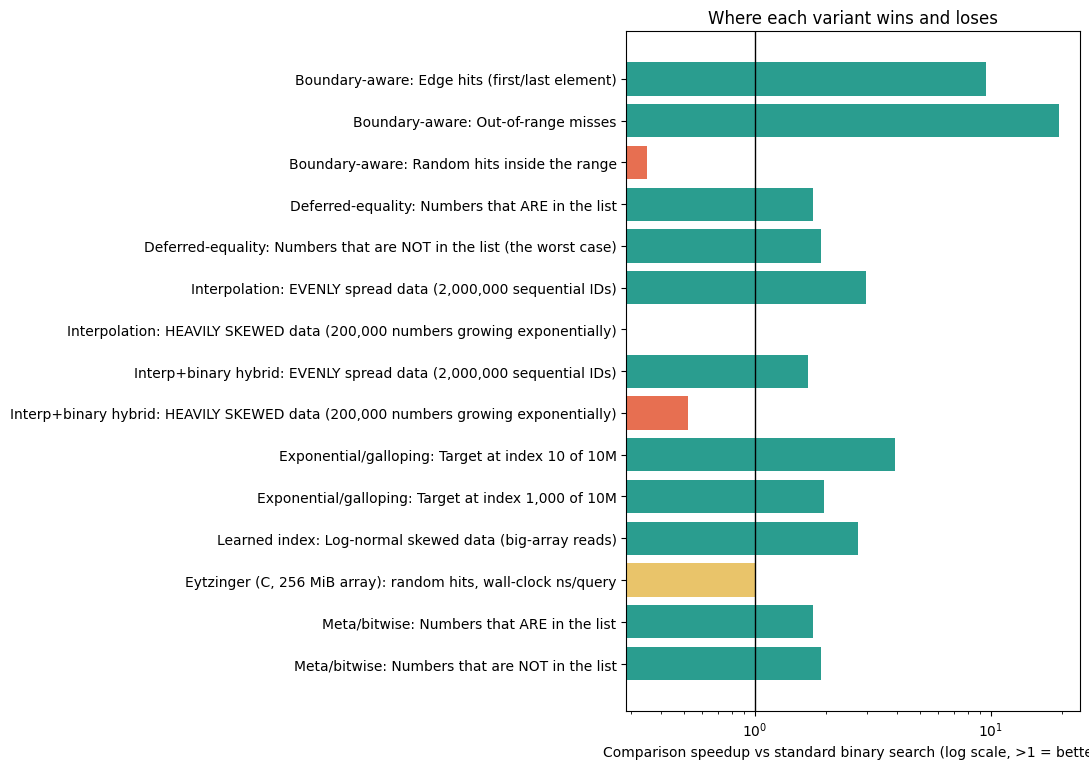

In [13]:
df = pd.DataFrame(RESULTS)
score = np.where(df.scenario.str.startswith("7"), df.time_speedup, df.normal_cmp / df.tech_cmp)   # Eytzinger is judged on wall-clock (C)
df["verdict"] = np.where(score >= 1.2, "WIN", np.where(score >= 0.8, "neutral", "LOSS"))
df["cmp_speedup"] = df["cmp_speedup"].round(2)
df["time_speedup"] = df["time_speedup"].round(2)
def _plain(r):
    return f"{_times(r)} less work" if r >= 1.2 else (f"{_times(1 / r)} MORE work" if r <= 0.8 else "about the same")
raw_ratio = np.where(df.scenario.str.startswith("7"), df.time_speedup, df.normal_cmp / df.tech_cmp)
df["how_much_better"] = [_plain(v) for v in raw_ratio]
df["Technique"] = df.scenario.str.split(" ", n=1).str[1]
df["normal_txt"] = [(_num(v) if not sc.startswith("7") else "-") for v, sc in zip(df.normal_cmp, df.scenario)]
df["tech_txt"] = [(_num(v) if not sc.startswith("7") else "-") for v, sc in zip(df.tech_cmp, df.scenario)]
df.loc[df.scenario.str.startswith("7"), ["normal_txt", "tech_txt"]] = ["see C benchmark", "see C benchmark"]
view = df[["Technique", "workload", "normal_txt", "tech_txt", "how_much_better", "verdict"]].rename(columns={
    "workload": "Situation tested", "normal_txt": "Normal search (comparisons)", "tech_txt": "This technique (comparisons)",
    "how_much_better": "Difference", "verdict": "Result"})
print("Comparisons per search - fewer is better. (Row 'Eytzinger' is judged on real speed in C instead.)\n")
print(view.to_string(index=False))

try:
    import matplotlib.pyplot as plt
    fig, ax = plt.subplots(figsize=(11, 0.42 * len(df) + 1.5))
    labels = [f"{s.split(' ',1)[1] if s[0].isdigit() else s}: {w}" for s, w in zip(df.scenario, df.workload)]
    colors = ["#2a9d8f" if v >= 1.2 else ("#e9c46a" if v >= 0.8 else "#e76f51") for v in df.cmp_speedup]
    ax.barh(labels[::-1], df.cmp_speedup[::-1], color=colors[::-1])
    ax.axvline(1, color="black", lw=1)
    ax.set_xscale("log")
    ax.set_xlabel("Comparison speedup vs standard binary search (log scale, >1 = better)")
    ax.set_title("Where each variant wins and loses")
    plt.tight_layout(); plt.show()
except ImportError:
    print("(install matplotlib to see the chart)")

### Complexity summary

| Technique | Best | Average | Worst | Extra space | Needs |
|---|---|---|---|---|---|
| Standard binary search | $O(1)$ | $O(\log N)$ | $O(\log N)$ | $O(1)$ | sorted |
| 1 Boundary-aware | $O(1)$ | $O(\log N)$ (3x constant) | $O(\log N)$ | $O(1)$ | sorted, edge-heavy queries |
| 2 Deferred-equality | $O(\log N)$ | $O(\log N)$ | $O(\log N)$, half the comparisons | $O(1)$ | sorted |
| 3 Interpolation | $O(1)$ | $O(\log\log N)$ | $O(N)$ | $O(1)$ | numeric, uniform |
| 4 Interp + binary hybrid | $O(1)$ | $O(\log\log N)$ (uniform) | $O(\log N)$ | $O(1)$ | numeric |
| 5 Exponential / galloping | $O(1)$ | $O(\log i)$ | $O(\log N)$ | $O(1)$ | sorted, or unbounded |
| 6 Learned index | $O(1)$ | $O(\log K + \log e)$ | $O(\log K + \log e)$ (bounded by build error) | $O(K)$ | numeric, static data |
| 7 Eytzinger layout | $O(\log N)$ | $O(\log N)$, ~3x faster real time | $O(\log N)$ | $O(N)$ | large static array |
| 8 Meta / bitwise | $O(\log N)$ | $O(\log N)$ (fixed steps) | $O(\log N)$ | $O(1)$ | sorted |

### Decision guide

* **Know nothing about the data?** Deferred-equality (2) is the strict upgrade over the textbook loop.
* **Queries hit the newest / oldest record, or many misses are out of range?** Boundary-aware (1).
* **Evenly spread numeric keys?** Interpolation with the hybrid safety net (4), never raw (3) in production.
* **Size unknown, streaming, or target near the front?** Galloping (5).
* **Skewed but static, read-heavy data (indexes, warehouse metadata)?** Learned index (6).
* **Huge static arrays and latency-critical reads?** Eytzinger (7) or a cache-line-wide B-tree.
* **Compiled hot loop where branch prediction matters?** Bitwise / branchless (8).

### Other techniques worth a look (not implemented here)

| Technique | Why it is interesting |
|---|---|
| **Binary search on the answer** (parametric search) | Search a *monotonic predicate* instead of an array (minimum ship capacity, minimum speed to finish on time). The most-used variant in interviews and capacity planning. |
| **Static B-tree / S-tree layouts** | Pack 16 keys per cache line and use SIMD to compare them all at once: the practical successor to Eytzinger (Algorithmica, Khuong & Morin's *"Array Layouts for Comparison-Based Searching"*). |
| **Fibonacci search** | Splits by Fibonacci numbers using only additions and subtractions; historically useful on tape and hardware without fast division. |
| **Fractional cascading** | Searching the *same key* in $k$ sorted lists in $O(\log N + k)$ instead of $O(k\log N)$. |
| **Bentley-Yao / unbounded search** | The optimal $O(\log i)$ generalisation of galloping. |

### Caveat on the Python timings

Python's interpreter overhead hides memory and branch effects, and `time.perf_counter` numbers vary by machine and run. Trust the **comparison counts** for algorithmic claims, and the **C benchmark** for hardware claims. If a wall-clock number in your run differs from what is described in a "Reading the result" cell, the comparison counts are the ground truth.